# Student Marks Prediction using Linear Regression

**Problem Statement:** Predict the marks a student will score based on the number of hours they study.

**Type of problem:** Supervised Learning – Regression (one input feature, one continuous output)

**Workflow followed in this project**

Define Problem → Collect Data → Understand/Clean Data → Choose X and y → Split into Train and Test → Create Linear Regression Model → Train Model → Model learns m and c → Make Predictions → Compare Actual vs Predicted → Evaluate Model

## Step 1: Define the Problem
We want to know whether study hours can be used to predict a student's marks. The relationship is assumed to be a straight line:

**Marks = m × Hours + c**

where `m` is the slope (marks gained per extra hour of study) and `c` is the intercept (expected marks at 0 hours).

## Step 2: Collect Data
Importing the required libraries and creating the dataset of 10 students. It has two columns: `Hours` (study hours per day) and `Marks` (marks out of 100).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

In [2]:
data = {
    'Hours': [1.5, 2.0, 2.5, 3.5, 4.0, 5.0, 5.5, 6.5, 7.5, 8.5],
    'Marks': [22, 28, 31, 40, 45, 52, 58, 66, 73, 85],
}
df = pd.DataFrame(data)
df.head()

,Hours,Marks
0,1.5,22
1,2.0,28
2,2.5,31
3,3.5,40
4,4.0,45


## Step 3: Understand and Clean the Data

In [3]:
print('Shape of dataset:', df.shape)
print()
df.info()

Shape of dataset: (10, 2)

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Hours   10 non-null     float64
 1   Marks   10 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 292.0 bytes


In [4]:
df.describe()

,Hours,Marks
count,10.000000,10.000000
mean,4.650000,50.000000
std,2.369365,20.634383
min,1.500000,22.000000
25%,2.750000,33.250000
50%,4.500000,48.500000
75%,6.250000,64.000000
max,8.500000,85.000000


In [5]:
print('Missing values:')
print(df.isnull().sum())
print()
print('Duplicate rows:', df.duplicated().sum())

Missing values:
Hours    0
Marks    0
dtype: int64

Duplicate rows: 0


**Observation:** There are no missing values, so no imputation is needed. The dataset is small (10 students). Marks lie between 0 and 100 and hours are positive, so the data looks valid.

In [6]:
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after removing duplicates:', df.shape)

Shape after removing duplicates: (10, 2)


### Visualising the relationship

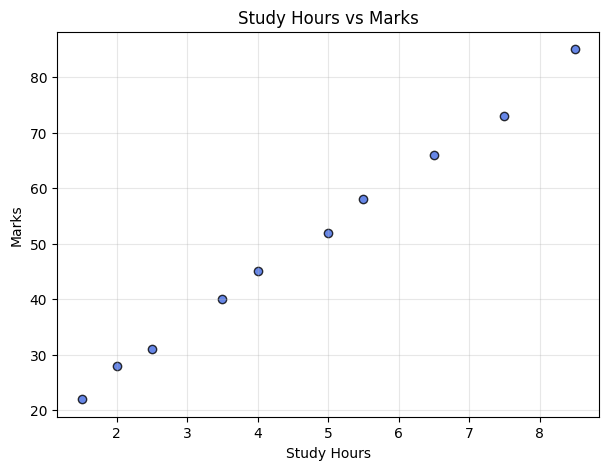

In [7]:
plt.figure(figsize=(7,5))
plt.scatter(df['Hours'], df['Marks'], color='royalblue', edgecolor='k', alpha=0.8)
plt.title('Study Hours vs Marks')
plt.xlabel('Study Hours')
plt.ylabel('Marks')
plt.grid(alpha=0.3)
plt.show()

In [8]:
print('Correlation between Hours and Marks:', round(df['Hours'].corr(df['Marks']), 4))

Correlation between Hours and Marks: 0.9988


**Observation:** The points rise in a nearly straight line and the correlation is close to +1. This shows a strong positive linear relationship, so Linear Regression is a suitable model.

## Step 4: Choose X and y
- **X (independent variable / feature):** Hours
- **y (dependent variable / target):** Marks

X is kept 2-dimensional (double brackets) because scikit-learn expects that shape for features.

In [9]:
X = df[['Hours']]
y = df['Marks']
print('X shape:', X.shape)
print('y shape:', y.shape)

X shape: (10, 1)
y shape: (10,)


## Step 5: Split into Train and Test
The dataset has only 10 students, so 70% (7 students) is used for training and 30% (3 students) for testing. `random_state=42` makes the split reproducible.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print('Training samples:', X_train.shape[0])
print('Testing samples :', X_test.shape[0])

Training samples: 7
Testing samples : 3


## Step 6: Create Linear Regression Model

In [11]:
model = LinearRegression()

## Step 7: Train Model
`fit()` trains the model on the training data.

In [12]:
model.fit(X_train, y_train)
print('Model trained successfully')

Model trained successfully


## Step 8: Model learns m and c
After training, the model has learned the best-fit line `Marks = m × Hours + c`.

In [13]:
m = model.coef_[0]
c = model.intercept_
print(f'Slope (m)     : {m:.4f}')
print(f'Intercept (c) : {c:.4f}')
print(f'\nEquation: Marks = {m:.2f} x Hours + {c:.2f}')

Slope (m)     : 8.9371
Intercept (c) : 8.7160

Equation: Marks = 8.94 x Hours + 8.72


**Interpretation:** For every extra hour of study, the predicted marks increase by about `m` marks. The intercept `c` is the predicted marks for a student who studies 0 hours.

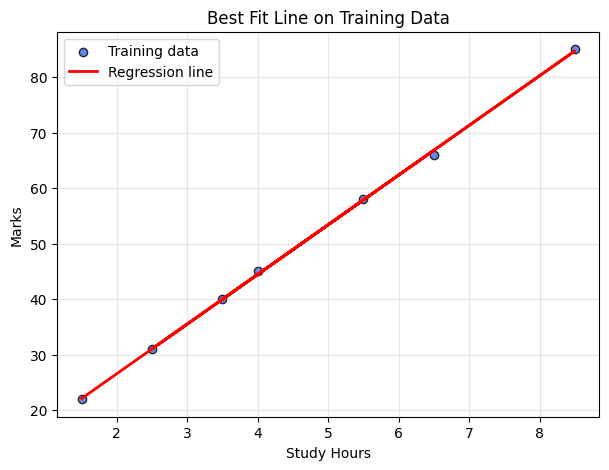

In [14]:
plt.figure(figsize=(7,5))
plt.scatter(X_train, y_train, color='royalblue', label='Training data', edgecolor='k', alpha=0.8)
plt.plot(X_train, model.predict(X_train), color='red', linewidth=2, label='Regression line')
plt.title('Best Fit Line on Training Data')
plt.xlabel('Study Hours')
plt.ylabel('Marks')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Step 9: Make Predictions
Predicting marks for the test set (data the model has never seen).

In [15]:
y_pred = model.predict(X_test)
y_pred

array([75.74442191, 26.59026369, 53.40162272])

## Step 10: Compare Actual vs Predicted

In [16]:
comparison = pd.DataFrame({
    'Hours': X_test['Hours'].values,
    'Actual Marks': y_test.values,
    'Predicted Marks': y_pred.round(2),
})
comparison['Error'] = (comparison['Actual Marks'] - comparison['Predicted Marks']).round(2)
comparison

,Hours,Actual Marks,Predicted Marks,Error
0,7.5,73,75.74,-2.74
1,2.0,28,26.59,1.41
2,5.0,52,53.40,-1.40


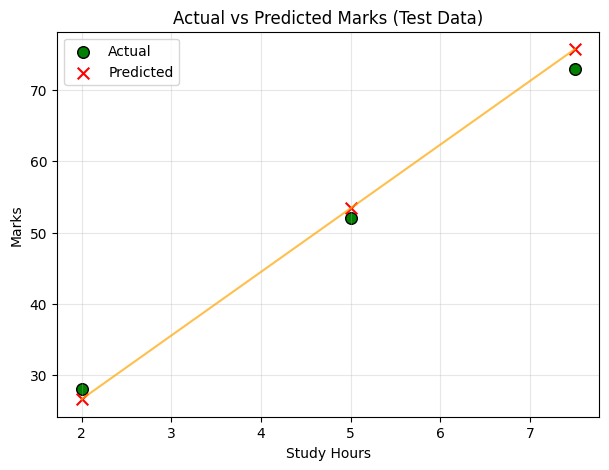

In [17]:
plt.figure(figsize=(7,5))
plt.scatter(X_test, y_test, color='green', label='Actual', edgecolor='k', s=70)
plt.scatter(X_test, y_pred, color='red', label='Predicted', marker='x', s=70)
plt.plot(X_test.sort_values('Hours'), model.predict(X_test.sort_values('Hours')), color='orange', alpha=0.7)
plt.title('Actual vs Predicted Marks (Test Data)')
plt.xlabel('Study Hours')
plt.ylabel('Marks')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Step 11: Evaluate Model

| Metric | Meaning |
|---|---|
| **MAE** (Mean Absolute Error) | Average size of the errors, in marks. Lower is better. |
| **MSE** (Mean Squared Error) | Average of squared errors; punishes large errors more. Lower is better. |
| **RMSE** (Root Mean Squared Error) | Square root of MSE; in the same units as marks. Lower is better. |
| **R² Score** | Proportion of variation in marks explained by study hours. Closer to 1 is better. |

In [18]:
mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)

print(f'MAE   : {mae:.4f}')
print(f'MSE   : {mse:.4f}')
print(f'RMSE  : {rmse:.4f}')
print(f'R2    : {r2:.4f}')

MAE   : 1.8519
MSE   : 3.8279
RMSE  : 1.9565
R2    : 0.9887


In [19]:
results = pd.DataFrame({'Metric': ['MAE', 'MSE', 'RMSE', 'R-Squared'],
                        'Value': [mae, mse, rmse, r2]}).round(4)
results

,Metric,Value
0,MAE,1.8519
1,MSE,3.8279
2,RMSE,1.9565
3,R-Squared,0.9887


In [20]:
# Compare train and test R2
print('Train R2:', round(model.score(X_train, y_train), 4))
print('Test  R2:', round(model.score(X_test, y_test), 4))

Train R2: 0.9996
Test  R2: 0.9887


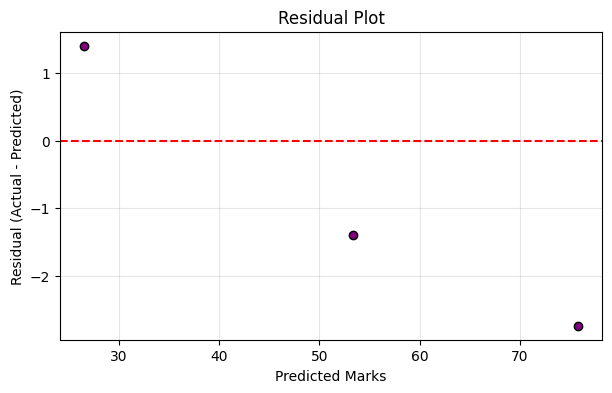

In [21]:
residuals = y_test - y_pred
plt.figure(figsize=(7,4))
plt.scatter(y_pred, residuals, color='purple', edgecolor='k')
plt.axhline(0, color='red', linestyle='--')
plt.title('Residual Plot')
plt.xlabel('Predicted Marks')
plt.ylabel('Residual (Actual - Predicted)')
plt.grid(alpha=0.3)
plt.show()

**Observation:** The residuals are scattered randomly around zero with no clear pattern, which supports the assumption that a linear model fits this data well.

## Predicting Marks for a New Student

In [22]:
def predict_marks(hours):
    new = pd.DataFrame({'Hours': [hours]})
    return model.predict(new)[0]

for h in [2, 5, 7.5, 9]:
    print(f'A student studying {h} hours is predicted to score about {predict_marks(h):.1f} marks')

A student studying 2 hours is predicted to score about 26.6 marks
A student studying 5 hours is predicted to score about 53.4 marks
A student studying 7.5 hours is predicted to score about 75.7 marks
A student studying 9 hours is predicted to score about 89.2 marks


## Conclusion

- A Linear Regression model was built to predict student marks from study hours, following the complete machine learning workflow.
- The scatter plot and correlation showed a strong positive linear relationship between hours studied and marks.
- The model learned the equation **Marks = m × Hours + c** (values shown in Step 8).
- On unseen test data the model achieved low MAE, MSE and RMSE and a high R² score (see Step 11), so it explains most of the variation in marks.
- Train and test R² are both high, which shows the model generalises well to the students it did not see during training.

**Limitations**
- Only one feature (study hours) is used. Real marks also depend on attendance, sleep, previous grades, quality of study, etc.
- The dataset has only 10 students and the test set has just 3, so the metrics can change noticeably with a different split or more data.
- A linear model cannot capture a saturation effect (e.g. very long hours giving diminishing returns). Marks may be predicted above 100 for very large inputs.

**Future Scope**
- Add more features and use Multiple Linear Regression.
- Try Polynomial Regression or tree-based models and compare metrics.
- Use a larger real-world dataset and cross-validation for more reliable metrics.